### The objective of this notebook is to filter the dataset for VEGRF-2 

The filteration will be based on orally bioavailable compounds

For a molecule to be a "lead" molecule it should follow Lipinski's rule of five (Ro5):
- Molecular weight (MWT) ≤ 500 Da. This is the size of the package. A very large molecule has trouble squeezing through the gut wall.
- LogP (octanol-water coefficient) ≤ 5. This measures how oily versus watery the molecule is. If it’s too oily, it won’t dissolve in the watery gut and blood and tends to get stuck in fat. If it’s too watery, it can’t pass through the oily cell membrane. You want a balance.
- Hydrogen bond donors (HBD) ≤ 5. These are the molecule’s “sticky hands” (mostly OH and NH groups) that cling to water.
- Hydrogen bond acceptors (HBA) ≤ 10. These are the sticky spots on the other side (mostly N and O atoms).

The last two matter because a molecule has to shed its water coat to slip through the cell membrane. The more sticky spots it has, the harder that is.

In [2]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, PandasTools


In [3]:
molecules = pd.read_csv("data/VEGFR-2.csv")
print(molecules.shape)
molecules.head(10)

(8954, 5)


,molecule_chembl_id,IC50,IC50_units,smiles,pIC50
0,CHEMBL5189340,0.023,nM,CN(C)c1ccc(/C=N/NC(=O)Cn2nc(Cc3ccc(Cl)cc3)c3cc...,10.638272
1,CHEMBL429743,0.030,nM,COc1cc2nccc(Oc3ccc4c(C(=O)Nc5ccc(Cl)cc5)cccc4c...,10.522879
2,CHEMBL5557999,0.100,nM,Cc1cc(C)nc(NS(=O)(=O)c2ccc(/N=N/c3ccc(C4=NCC(=...,10.000000
3,CHEMBL5411585,0.110,nM,COc1cc2c(Oc3ccc(NC(=O)Nc4ccc(C(F)(F)F)cc4)c(Cl...,9.958607
4,CHEMBL5186748,0.120,nM,CNC(=O)c1cc(Oc2ccc(NC(=O)c3nn(-c4ccc(Cl)cc4)cc...,9.920819
5,CHEMBL3586072,0.140,nM,CNC(=O)c1ccc(-c2ccc(NC(=O)Nc3cc(Br)cc(C(F)(F)F...,9.853872
6,CHEMBL3093581,0.140,nM,O=C(Nc1ccc(Oc2ccc3nc(NC(=O)C4CC4)cn3c2)c(F)c1)...,9.853872
7,CHEMBL3586071,0.150,nM,CNC(=O)c1cc(-c2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)...,9.823909
8,CHEMBL1289494,0.160,nM,COc1cc2nccc(Oc3ccc(NC(=O)Nc4cc(C)on4)c(Cl)c3)c...,9.795880
9,CHEMBL2348996,0.190,nM,Cc1cc(C(=O)Nc2cccc(Oc3ccc4nc(NC(=O)C5CC5)cn4n3...,9.721246


In [4]:
# writing the function that would filter the molecules based on the Lipinski's rule of five
def lipinski_filter(smiles):
    molecule = Chem.MolFromSmiles(smiles)
    
    molecular_weight = Descriptors.MolWt(molecule)
    logp = Descriptors.MolLogP(molecule)
    h_bond_donors = Descriptors.NumHDonors(molecule)
    h_bond_acceptors = Descriptors.NumHAcceptors(molecule)
    
    conditions = [
        molecular_weight <= 500,
        logp <= 5,
        h_bond_donors <= 5,
        h_bond_acceptors <= 10]
    
    ro5_fulfilled = sum(conditions) >= 3 # a molecule is considered to fulfill Lipinski's rule of five if it meets at least 3 out of the 4 conditions
    return pd.Series([molecular_weight, logp, h_bond_donors, h_bond_acceptors, ro5_fulfilled], 
                        index=["Molecular Weight", "LogP", "H-Bond Donors", "H-Bond Acceptors", "Ro5 Fulfilled"])

In [5]:
ro5_properties = molecules["smiles"].apply(lipinski_filter)
ro5_properties.head(10)

,Molecular Weight,LogP,H-Bond Donors,H-Bond Acceptors,Ro5 Fulfilled
0,473.964,3.85700,1,5,True
1,484.939,7.10320,1,5,True
2,574.066,5.77684,1,8,False
3,616.040,7.61160,2,7,False
4,489.919,3.99352,2,6,True
5,493.283,5.53350,3,3,True
6,523.524,5.01740,2,5,False
7,448.832,5.42440,3,3,True
8,454.870,5.63812,2,7,True
9,431.456,3.16432,2,6,True


In [6]:
molecule = pd.concat([molecules, ro5_properties], axis=1)
molecule.head(10)

,molecule_chembl_id,IC50,IC50_units,smiles,pIC50,Molecular Weight,LogP,H-Bond Donors,H-Bond Acceptors,Ro5 Fulfilled
0,CHEMBL5189340,0.023,nM,CN(C)c1ccc(/C=N/NC(=O)Cn2nc(Cc3ccc(Cl)cc3)c3cc...,10.638272,473.964,3.85700,1,5,True
1,CHEMBL429743,0.030,nM,COc1cc2nccc(Oc3ccc4c(C(=O)Nc5ccc(Cl)cc5)cccc4c...,10.522879,484.939,7.10320,1,5,True
2,CHEMBL5557999,0.100,nM,Cc1cc(C)nc(NS(=O)(=O)c2ccc(/N=N/c3ccc(C4=NCC(=...,10.000000,574.066,5.77684,1,8,False
3,CHEMBL5411585,0.110,nM,COc1cc2c(Oc3ccc(NC(=O)Nc4ccc(C(F)(F)F)cc4)c(Cl...,9.958607,616.040,7.61160,2,7,False
4,CHEMBL5186748,0.120,nM,CNC(=O)c1cc(Oc2ccc(NC(=O)c3nn(-c4ccc(Cl)cc4)cc...,9.920819,489.919,3.99352,2,6,True
5,CHEMBL3586072,0.140,nM,CNC(=O)c1ccc(-c2ccc(NC(=O)Nc3cc(Br)cc(C(F)(F)F...,9.853872,493.283,5.53350,3,3,True
6,CHEMBL3093581,0.140,nM,O=C(Nc1ccc(Oc2ccc3nc(NC(=O)C4CC4)cn3c2)c(F)c1)...,9.853872,523.524,5.01740,2,5,False
7,CHEMBL3586071,0.150,nM,CNC(=O)c1cc(-c2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)...,9.823909,448.832,5.42440,3,3,True
8,CHEMBL1289494,0.160,nM,COc1cc2nccc(Oc3ccc(NC(=O)Nc4cc(C)on4)c(Cl)c3)c...,9.795880,454.870,5.63812,2,7,True
9,CHEMBL2348996,0.190,nM,Cc1cc(C(=O)Nc2cccc(Oc3ccc4nc(NC(=O)C5CC5)cn4n3...,9.721246,431.456,3.16432,2,6,True


In [7]:
# to find the number of molecules that fulfill Lipinski's rule of five and those that do not compared to the total number of molecules in the dataset
total_molecules = molecule.shape[0]
ro5_fulfilled = molecule["Ro5 Fulfilled"].sum()
ro5_not_fulfilled = total_molecules - ro5_fulfilled

print(f"Total molecules: {total_molecules}")
print(f"Molecules that fulfill Ro5: {ro5_fulfilled}")
print(f"Molecules that do not fulfill Ro5: {ro5_not_fulfilled}")

Total molecules: 8954
Molecules that fulfill Ro5: 7261
Molecules that do not fulfill Ro5: 1693


In [10]:
# downloading the whole dataset of molecules 
molecule.to_csv("data/VEGFR-2_All_Ro5.csv", index=True)


In [11]:
# downloading the dataset of molecules that fulfill Lipinski's rule of five
molecules_ro5_fulfilled = molecule[molecule["Ro5 Fulfilled"] == True]
molecules_ro5_fulfilled.to_csv("data/VEGFR-2_Ro5_fulfilled.csv")

### Visualizing Ro5 Analysis 

In [12]:
# calculating the mean and std 
def mean_std(frame):
    stats = frame.describe().T[["mean", "std"]]
    return stats



    
    
    

In [13]:
ro5_fulfilled_stats = mean_std(molecules_ro5_fulfilled[["Molecular Weight", "LogP", "H-Bond Donors", "H-Bond Acceptors"]])

ro5_fulfilled_stats 

,mean,std
Molecular Weight,426.065604,72.811339
LogP,4.235710,1.154197
H-Bond Donors,2.242804,1.131136
H-Bond Acceptors,5.509847,1.737392


In [14]:
ro5_violation_stats = mean_std(molecule[molecule["Ro5 Fulfilled"] == False][["Molecular Weight", "LogP", "H-Bond Donors", "H-Bond Acceptors"]])
ro5_violation_stats 

,mean,std
Molecular Weight,558.524887,63.380224
LogP,6.052654,0.922384
H-Bond Donors,2.502658,1.256011
H-Bond Acceptors,6.706438,1.673232


helper functions for radar plotting

In [15]:
def _scale_by_thresholds(stats, thresholds, scaled_threshold):
    # Raise error if scaling keys and data_stats indicies are not matching
    for property_name in stats.index:
        if property_name not in thresholds.keys():
            raise KeyError(f"Add property '{property_name}' to scaling variable.")
    # Scale property data
    stats_scaled = stats.apply(lambda x: x / thresholds[x.name] * scaled_threshold, axis=1)
    return stats_scaled


def _define_radial_axes_angles(n_axes):
    """Define angles (radians) for radial (x-)axes depending on the number of axes."""
    x_angles = [i / float(n_axes) * 2 * math.pi for i in range(n_axes)]
    x_angles += x_angles[:1]
    return x_angles

In [29]:
def plot_radar(
    y,
    thresholds,
    scaled_threshold,
    properties_labels,
    y_max=None,
    output_path=None,
):


    # Define radial x-axes angles -- uses our helper function!
    x = _define_radial_axes_angles(len(y))
    # Scale y-axis values with respect to a defined threshold -- uses our helper function!
    y = _scale_by_thresholds(y, thresholds, scaled_threshold)
    # Since our chart will be circular we append the first value of each property to the end
    y = pd.concat([y, y.head(1)])

    # Set figure and subplot axis
    plt.figure(figsize=(6, 6))
    ax = plt.subplot(111, polar=True)

    # Plot data
    ax.fill(x, [scaled_threshold] * len(x), "cornflowerblue", alpha=0.2)
    ax.plot(x, y["mean"], "b", lw=3, ls="-")
    ax.plot(x, y["mean"] + y["std"], "orange", lw=2, ls="--")
    ax.plot(x, y["mean"] - y["std"], "orange", lw=2, ls="-.")

    # From here on, we only do plot cosmetics
    # Set 0° to 12 o'clock
    ax.set_theta_offset(math.pi / 2)
    # Set clockwise rotation
    ax.set_theta_direction(-1)

    # Set y-labels next to 180° radius axis
    ax.set_rlabel_position(180)
    # Set number of radial axes' ticks and remove labels
    plt.xticks(x, [])
    # Get maximal y-ticks value
    if not y_max:
        y_max = int(ax.get_yticks()[-1])
    # Set axes limits
    plt.ylim(0, y_max)
    # Set number and labels of y axis ticks
    plt.yticks(
        range(1, y_max),
        ["5" if i == scaled_threshold else "" for i in range(1, y_max)],
        fontsize=16,
    )

    # Draw ytick labels to make sure they fit properly
    # Note that we use [:1] to exclude the last element which equals the first element (not needed here)
    for i, (angle, label) in enumerate(zip(x[:-1], properties_labels)):
        if angle == 0:
            ha = "center"
        elif 0 < angle < math.pi:
            ha = "left"
        elif angle == math.pi:
            ha = "center"
        else:
            ha = "right"
        ax.text(
            x=angle,
            y=y_max + 1,
            s=label,
            size=16,
            horizontalalignment=ha,
            verticalalignment="center",
        )

    # Add legend relative to top-left plot
    labels = ("mean", "mean + std", "mean - std", "rule of five area")
    ax.legend(labels, loc=(1.1, 0.7), labelspacing=0.3, fontsize=16)

    # Save plot - use bbox_inches to include text boxes
    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches="tight", transparent=True)

    plt.show()

In [30]:
thresholds = {
    "Molecular Weight": 500,
    "LogP": 5,
    "H-Bond Donors": 5,
    "H-Bond Acceptors": 10,
}
scaled_threshold = 5
properties_labels = [
    "Molecular weight (Da) / 100",
    "# HBA / 2",
    "# HBD",
    "LogP",
]
y_max = 8

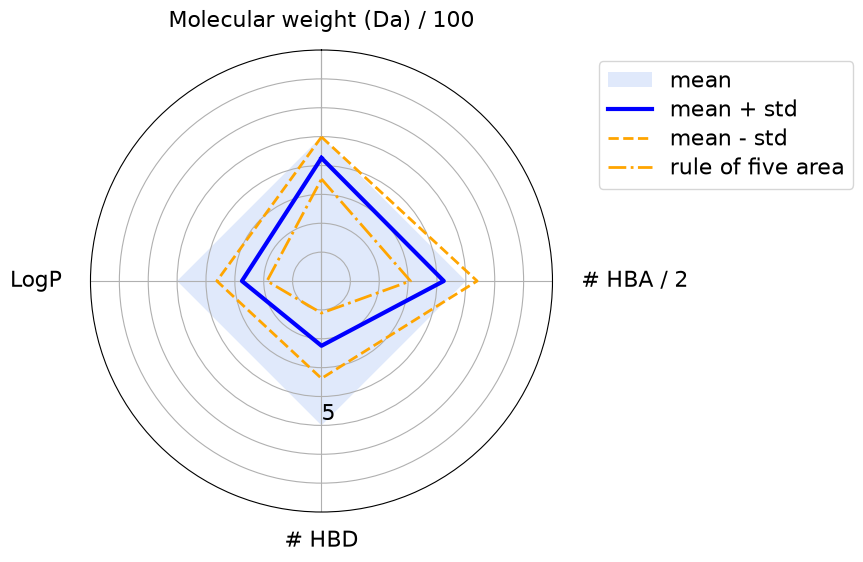

In [31]:
from pathlib import Path

output_path = Path("plots") / "ro5_fulfilled_radar_plot.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

plot_radar(
    y=ro5_fulfilled_stats,
    thresholds=thresholds,
    scaled_threshold=scaled_threshold,
    properties_labels=properties_labels,
    y_max=y_max,
    output_path=output_path,
)

The average molecule sits inside the safe zone on every spoke. But it’s close to the edge on size (MW) and on one of the two “sticky” counts (HBA), so many of these molecules only just squeeze in.

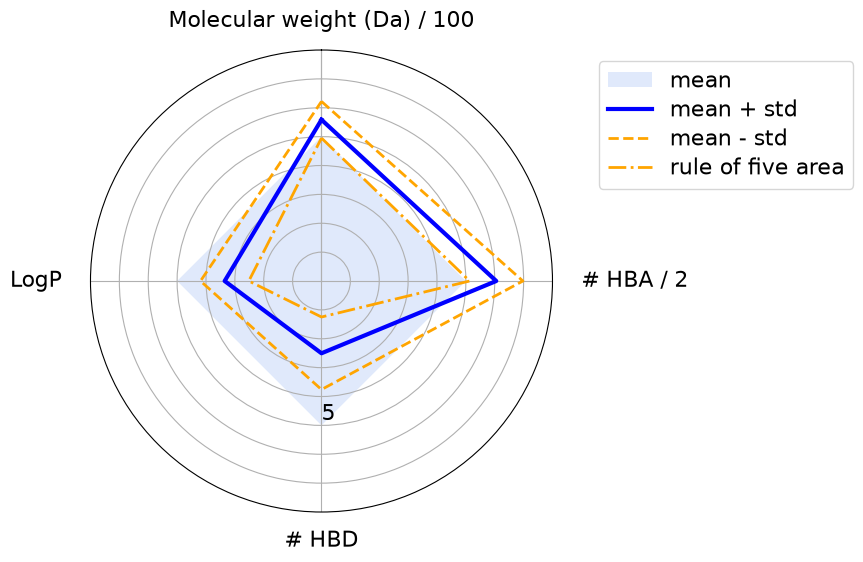

In [25]:
plot_radar(
    y=ro5_violation_stats,
    thresholds=thresholds,
    scaled_threshold=scaled_threshold,
    properties_labels=properties_labels,
    y_max=y_max,
    output_path=Path("plots") / "ro5_violation_radar_plot.png",
)

The average molecule is too big and has too many HBA sticky spots, so the blue line goes outside the safe zone on those two spokes.
The other two spokes (HBD and logP) are fine in both groups. That means the molecules fail mainly because they are large and have lots of oxygen and nitrogen atoms, not because they are too oily.


Big, very sticky molecules struggle to get through the gut wall into the blood, so the plot supports the idea that the second group is less likely to work as a pill.